# IPERLITE L2A spectral index change over the Camargue rice paddies

As a follow-up to the initial data loading workflow presented in [load-iperlite-stac.ipynb](../../20_data-discovery/iperlite/load-iperlite-stac.ipynb) and the pre/post wildfire comparison in [iperlite-wildfire.ipynb](../iperlite-wildfire/iperlite-wildfire.ipynb), this notebook applies the same openEO change-detection workflow to the IPERLITE **Level-2A** (top-of-canopy reflectance) collection.

The Camargue is the main rice-growing region of France: paddies are flooded and sown in late April to May, the crop emerges and tillers in June, reaches peak biomass around heading in August, and ripens before harvest in late September to October. Therefore, in this example we focus on capturing the key phenological stages of the rice crop using IPERLITE L2A data. We will compare the following three dates:

- **8 June 2026** - early season (flooded paddies, crop emergence)
- **8 August 2026** - peak biomass
- **10 September 2026** - ripening, shortly before harvest

> **Note** Please note that the notebook is intended to illustrate the workflow in openEO and provides example results rather than validated crop measurements.

For more information on the IPERLITE data and the available spectral indices, please refer to the [IPERLITE documentation](https://eo.belspo.be/nl/satellites-and-sensors/iperlite).

In [1]:
import openeo

connection = openeo.connect("openeo.terrascope.be").authenticate_oidc()

Authenticated using refresh token.


Let us start by defining the area of interest (AOI), the three acquisition dates, the bands for our analysis and the URL of the Terrascope STAC Catalogue.

The L2A assets are named `RTOC*` (top-of-canopy reflectance) instead of the `RTOA*` (top-of-atmosphere reflectance) assets of the L1C collection. The band numbering is identical, so the same band selection as in the [wildfire notebook](../iperlite-wildfire/iperlite-wildfire.ipynb) can be used.

In [2]:
IPERLITE_L2A = "https://stac.terrascope.be/collections/terrascope-iperlite-l2a-cog-v1"

# AOI over the Camargue rice paddies covered by all IPERLITE L2A acquisitions of the Camargue site.
aoi = {
    "type": "Polygon",
    "coordinates": [[
        [4.55, 43.56],
        [4.72, 43.56],
        [4.72, 43.66],
        [4.55, 43.66],
        [4.55, 43.56],
    ]],
}

early_period = ["2026-06-08", "2026-06-09"]
peak_period = ["2026-08-08", "2026-08-09"]
late_period = ["2026-09-10", "2026-09-11"]

# RTOC bands nearest to 531, 550, 570, 665, 680, 705, 750, 783, and 842 nm.
bands = ["RTOC18", "RTOC23", "RTOC33", "RTOC52", "RTOC58", "RTOC66", "RTOC84", "RTOC101", "RTOC122"]
print(f"Early window: {early_period}; peak window: {peak_period}; late window: {late_period}")

Early window: ['2026-06-08', '2026-06-09']; peak window: ['2026-08-08', '2026-08-09']; late window: ['2026-09-10', '2026-09-11']


Let us use the `load_stac` process to load the selected IPERLITE data. The subset is loaded for the AOI and date range instead of downloading complete scenes. The temporal extent spans all three acquisitions; the individual dates are selected later with `filter_temporal`.

In [3]:
cube = connection.load_stac(
    url=IPERLITE_L2A,
    spatial_extent=aoi,
    temporal_extent=[early_period[0], late_period[1]],
    bands=bands,
)

To follow the rice crop through the season we define the vegetation indices below.

- Normalised Difference Vegetation Index (**NDVI**) = (R842 - R665) / (R842 + R665): The NDVI gives an idea of the vegetation greenness and overall health ([Tucker, 1979](https://doi.org/10.1016/0034-4257(79)90013-0)). 
- Chlorophyll Index Red Edge (**CIre**) = R783 / R705 - 1: The CIre provides a measure of chlorophyll content in vegetation, complementing NDVI for dense canopies ([Gitelson et al., 2003](https://doi.org/10.1078/0176-1617-00887)). 
- Photochemical Reflectance Index (**PRI**) = (R531 - R570) / (R531 + R570): The PRI is a signal associated with photosynthetic light-use efficiency and xanthophyll-cycle activity; it may respond to physiological stress, but is also sensitive to illumination and canopy conditions ([Gamon et al., 1992](https://doi.org/10.1016/0034-4257(92)90059-S)).
- Chlorophyll Absorption Depth at 680 nm (**CAD680**) = 1 - R680 / Rcontinuum: With the CAD680, we estimate the depth of the chlorophyll absorption feature near 680 nm relative to a local spectral baseline. Here, Rcontinuum is linearly interpolated between 550 and 750 nm. This is a simplified continuum-depth calculation used in this example. [Yang et al. (2006)](https://doi.org/10.1631/jzus.2006.A2002) discuss a related chlorophyll absorption continuum index.

All four indices are ratios of reflectances, so they are independent of whether the backend returns reflectance in 0-1 units or as raw integers stored with a 0.0001 scale.

In [4]:
r531 = cube.band("RTOC18")
r550 = cube.band("RTOC23")
r570 = cube.band("RTOC33")
r665 = cube.band("RTOC52")
r680 = cube.band("RTOC58")
r705 = cube.band("RTOC66")
r750 = cube.band("RTOC84")
r783 = cube.band("RTOC101")
r842 = cube.band("RTOC122")

In [6]:
# calculate spectral indices
ndvi = ((r842 - r665) / (r842 + r665)).add_dimension(
    name="bands", label="NDVI", type="bands"
)
cire = (r783 / r705 - 1).add_dimension(
    name="bands", label="CIre", type="bands"
)
pri = ((r531 - r570) / (r531 + r570)).add_dimension(
    name="bands", label="PRI", type="bands"
)

continuum_680 = r550 + (r750 - r550) * (130 / 200)
cad680 = (1 - r680 / continuum_680).add_dimension(
    name="bands", label="CAD680", type="bands"
)
# merge all calculated indices into a single cube
indices = ndvi.merge_cubes(cire).merge_cubes(pri).merge_cubes(cad680)
indices

In order to analyze the phenological changes of the rice crop, we compare the early, peak, and late-season composites derived from the IPERLITE scenes.

Using openEO's standard processes such as `filter_temporal` and `reduce_dimension`, we create a composite for each of the three windows. The `filter_temporal` process selects the relevant acquisition and the `reduce_dimension` process computes a per-pixel median over the selected acquisitions. 

Two differences are then derived:

- **growth** = peak minus early: the change while the canopy develops between June and August.
- **ripening** = late minus peak: the change while the crop matures between August and September.

The two change cubes are merged into a single datacube with eight bands.

In [7]:
early_indices = indices.filter_temporal(early_period).reduce_dimension(
    dimension="t", reducer="median"
)
peak_indices = indices.filter_temporal(peak_period).reduce_dimension(
    dimension="t", reducer="median"
)
late_indices = indices.filter_temporal(late_period).reduce_dimension(
    dimension="t", reducer="median"
)

growth = (peak_indices - early_indices).rename_labels(
    dimension="bands",
    target=["dNDVI_growth", "dCIre_growth", "dPRI_growth", "dCAD680_growth"],
)
ripening = (late_indices - peak_indices).rename_labels(
    dimension="bands",
    target=["dNDVI_ripening", "dCIre_ripening", "dPRI_ripening", "dCAD680_ripening"],
)

change = growth.merge_cubes(ripening)
change

The `d` prefix means later minus earlier. Next, let us submit the resulting datacube with 8 bands as an as a batch job. In the cell below we also specify the output format to NetCDF. 

In [8]:
change.execute_batch(
    title="IPERLITE L2A spectral index change - Camargue rice",
    outputfile="change_detection_camargue.nc",
)

0:00:00 Job 'j-2611100821064031a25e2970fbf88d21': send 'start'
0:00:16 Job 'j-2611100821064031a25e2970fbf88d21': queued (progress 0%)
0:00:21 Job 'j-2611100821064031a25e2970fbf88d21': queued (progress 0%)
0:00:28 Job 'j-2611100821064031a25e2970fbf88d21': queued (progress 0%)
0:00:36 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 3.4%)
0:00:46 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 4.9%)
0:00:58 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 6.8%)
0:01:14 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 8.9%)
0:01:33 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 11.5%)
0:01:57 Job 'j-2611100821064031a25e2970fbf88d21': running (progress 14.5%)
0:02:27 Job 'j-2611100821064031a25e2970fbf88d21': finished (progress 100%)


<BatchJob job_id='j-2611100821064031a25e2970fbf88d21'>

In [9]:
import xarray as xr

change_ds = xr.open_dataset("change_detection_camargue.nc")
change_ds

<xarray.Dataset> Size: 13MB
Dimensions:           (y: 570, x: 698)
Coordinates:
  * y                 (y) float64 5kB 4.836e+06 4.836e+06 ... 4.824e+06
  * x                 (x) float64 6kB 6.25e+05 6.25e+05 ... 6.389e+05 6.389e+05
Data variables:
    crs               |S1 1B ...
    dNDVI_growth      (y, x) float32 2MB ...
    dCIre_growth      (y, x) float32 2MB ...
    dPRI_growth       (y, x) float32 2MB ...
    dCAD680_growth    (y, x) float32 2MB ...
    dNDVI_ripening    (y, x) float32 2MB ...
    dCIre_ripening    (y, x) float32 2MB ...
    dPRI_ripening     (y, x) float32 2MB ...
    dCAD680_ripening  (y, x) float32 2MB ...
Attributes:
    Conventions:  CF-1.9
    institution:  VITO Terrascope openEO API - 0.74.0a4.dev20261026+283
    description:  
    title:

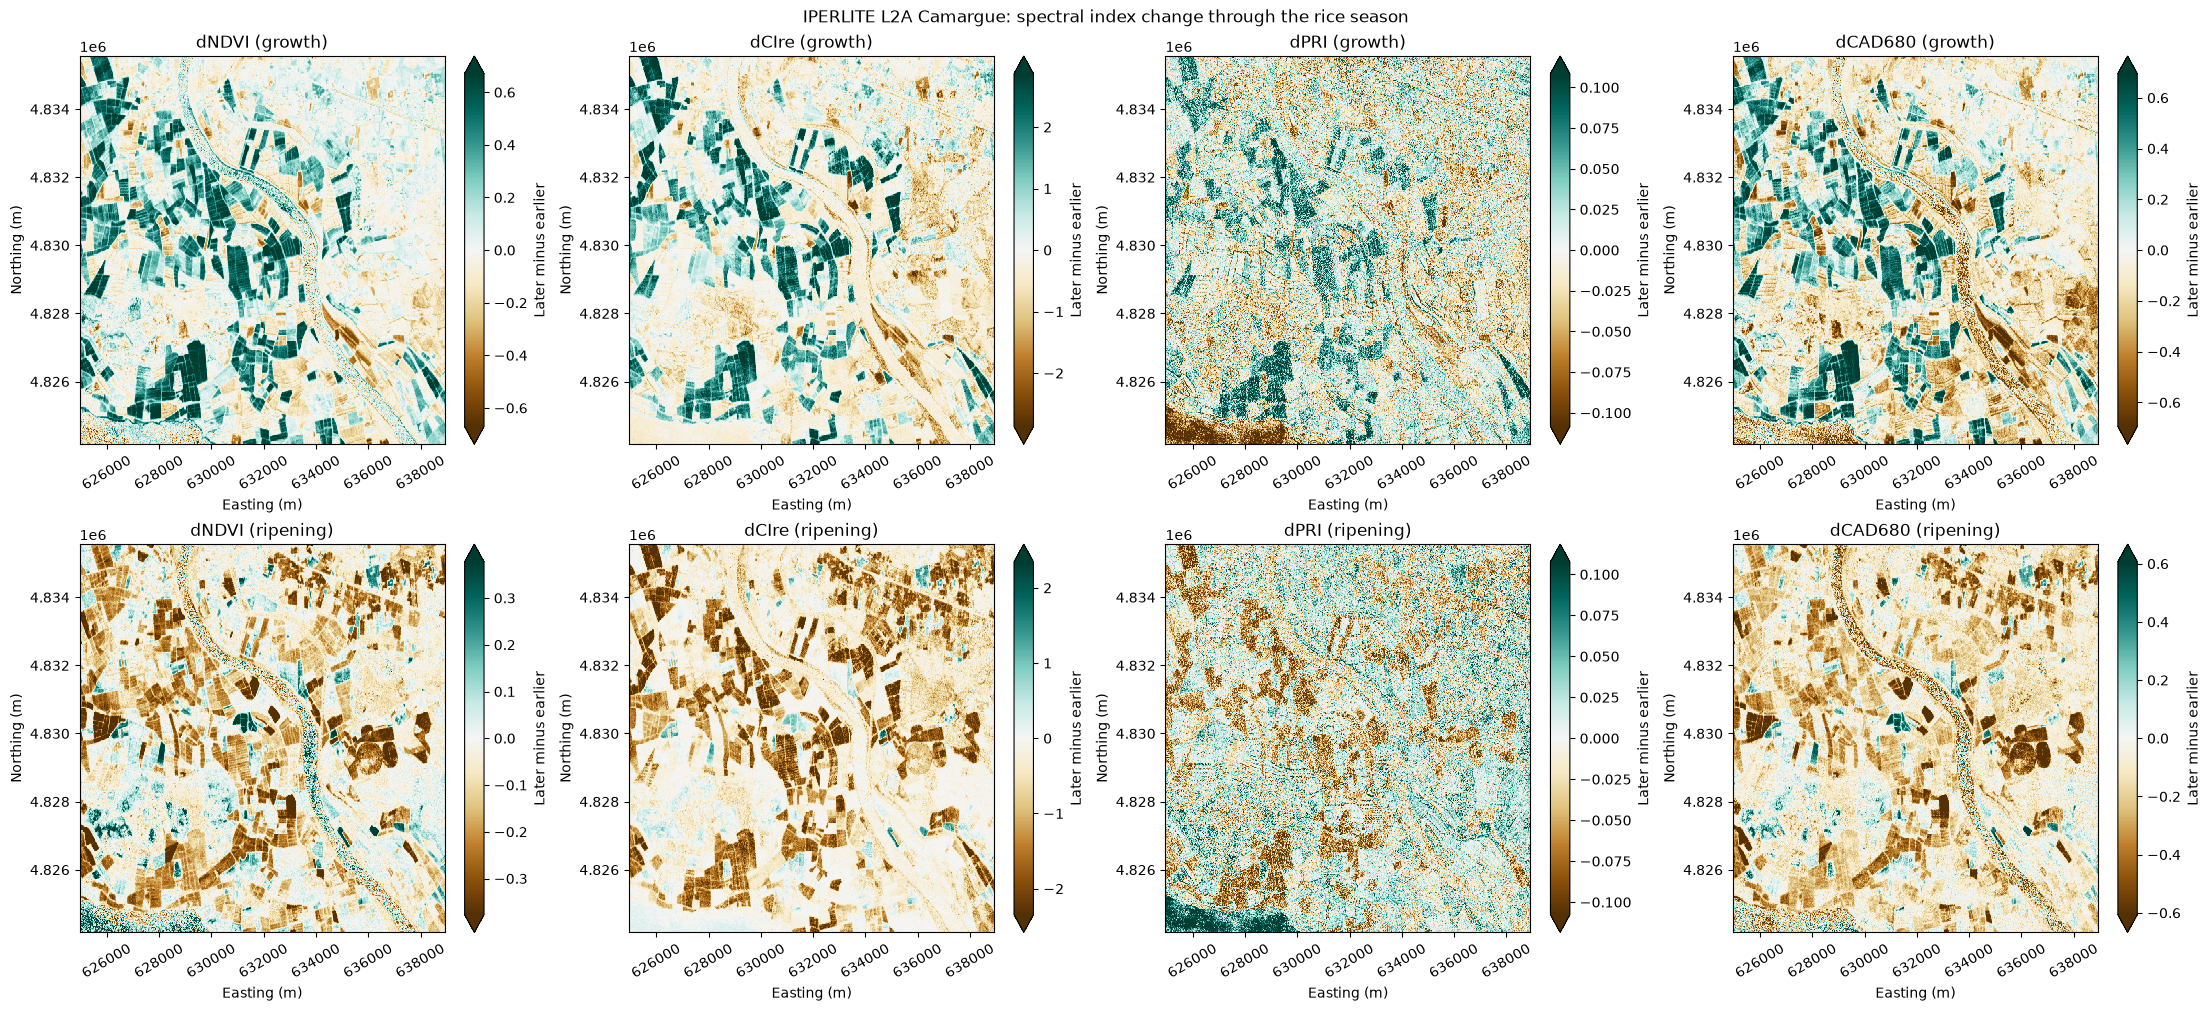

In [10]:
import matplotlib.pyplot as plt

index_names = ["dNDVI", "dCIre", "dPRI", "dCAD680"]
phases = ["growth", "ripening"]
fig, axes = plt.subplots(len(phases), len(index_names), figsize=(22, 10), constrained_layout=True)

for row, phase in zip(axes, phases):
    for ax, name in zip(row, index_names):
        # BrBG: brown = decrease (browning / senescence), blue-green = increase (greening)
        change_ds[f"{name}_{phase}"].plot(ax=ax, cmap="BrBG", center=0, robust=True, cbar_kwargs={"label": "Later minus earlier"})
        ax.set_title(f"{name} ({phase})")
        ax.set_xlabel("Easting (m)")
        ax.set_ylabel("Northing (m)")
        ax.tick_params(axis="x", labelrotation=30)

fig.suptitle("IPERLITE L2A Camargue: spectral index change through the rice season")
plt.show()